# 01 · MyBatis-Plus


## 本章来源与学习路线

本篇对应百度网盘 **`我的资源/day01-MybatisPlus/PPT/MybatisPlus.pptx»**，并核对了 **`资料/mp.sql»** 中的表结构。整理日期：2026-10-09。

源 PPTX 有 **72 页，其中 8 页为隐藏页**，网盘预览显示 64 页。以下页码按源文件顺序标注，隐藏页中的关联查询、配置加密和插件原理也纳入笔记。

课件预览：[MybatisPlus](https://pan.baidu.com/pfile/docview?path=%2F%E6%88%91%E7%9A%84%E8%B5%84%E6%BA%90%2Fday01-MybatisPlus%2FPPT%2FMybatisPlus.pptx&fsid=932566571143626&size=2606371&view_from=personal_file&md5=147fc84b4pfde379b42d7482cdddcf94&share=0&client=web&scene=main)。

| 学习阶段 | 对应页码 | 要解决的问题 |
| --- | --- | --- |
| 快速入门 | 4—16 | 怎样省去单表 CRUD 的重复 SQL |
| 核心功能 | 17—37 | 怎样组合条件、自定义 SQL、组织 Service |
| 扩展功能 | 38—61 | 怎样生成代码、关联数据、处理删除与类型转换 |
| 插件与分页 | 62—72 | 怎样拦截 SQL、实现分页接口与通用分页对象 |

**版本约定**：课件使用 MyBatis-Plus **3.5.3.1**。整理示例按 Java 11、Spring Boot 2.x 的常见项目结构书写；版本升级时应重新核对 starter 和插件依赖。文中省略常规 import，`@Data»、`@Getter»、`@RequiredArgsConstructor» 来自 Lombok，用来生成访问器或构造器。

**示例说明**：标注“课件方案”的内容来自课件；“整理示例”是依据课件重建的代码；“补充/改进”解释落地时的边界。已读取 PPT 和 SQL 预览，未完整读取或运行 `mp-demo» 工程。截图以附件嵌入，可离线阅读。


## 1. MyBatis-Plus 的定位与调用关系

使用 MyBatis 时，单表新增、按主键查询和修改经常只有表名、字段不同。**MyBatis-Plus（MP）在 MyBatis 上提供通用方法和 SQL 构造能力**，减少这类重复代码，同时保留 Mapper XML、自定义 SQL 和原有 MyBatis 能力。（课件第 2、7—9 页）

| 组成 | 职责 | 常见入口 |
| --- | --- | --- |
| `BaseMapper<T>» | 提供单表数据访问方法 | `insert»、`selectById»、`updateById» |
| Wrapper 条件构造器 | 根据 Java 调用构建 SQL 条件 | `eq»、`like»、`in»、`ge» |
| `IService<T>» / `ServiceImpl<M,T>» | 在通用 Mapper 上提供 Service 方法 | `save»、`list»、`saveBatch» |
| `Db» | 提供静态数据访问入口 | `Db.getById»、`Db.lambdaQuery» |
| `MybatisPlusInterceptor» | 拦截执行流程，组织内部插件 | 分页、乐观锁、多租户 |

`T» 表示实体类型，例如 `User»；`M» 表示 Mapper 类型，例如 `UserMapper»。

```text
HTTP 请求
    ↓
Controller：接收参数、返回结果
    ↓
Service：校验状态、处理业务、控制事务
    ↓
Mapper / BaseMapper：执行数据访问
    ↓
MyBatis：参数绑定、结果映射、调用 JDBC
    ↓
MySQL
```

MP 根据实体元信息生成通用 SQL。涉及复杂关联、聚合或业务更新时，仍需要判断 SQL 是否正确、索引是否合适，必要时自行编写。


## 2. 快速入门：依赖、数据源和 Mapper

要让 MP 的自动配置和通用 SQL 生效，需要引入匹配版本的 starter，再让 Spring 扫描 Mapper。（课件第 6—9、16 页）

**课件依赖**：用 MP starter 替换项目原有的 MyBatis starter，避免同时引入两套相互冲突的自动配置。

```xml
<dependency>
    <groupId>com.baomidou</groupId>
    <artifactId>mybatis-plus-boot-starter</artifactId>
    <version>3.5.3.1</version>
</dependency>
```

MySQL 驱动由项目依赖管理选择兼容版本。课件的 starter 面向 Spring Boot 2；迁移 Spring Boot 3 时需要 Java 17 及匹配的 MP 版本和 starter，不能只改版本号沿用所有配置。

**整理示例**：

```yaml
spring:
  datasource:
    url: jdbc:mysql://localhost:3306/mp
    username: ${DB_USERNAME}
    password: ${DB_PASSWORD}
    driver-class-name: com.mysql.cj.jdbc.Driver
```

```java
@SpringBootApplication
@MapperScan("com.itheima.mp.mapper")
public class MpDemoApplication {
    public static void main(String[] args) {
        SpringApplication.run(MpDemoApplication.class, args);
    }
}
```

```java
public interface UserMapper extends BaseMapper<User> {
    // 单表通用方法已由 BaseMapper 提供
}
```

`@MapperScan» 负责把指定包中的 Mapper 接口注册到 Spring。也可在各接口上使用 `@Mapper»，项目选择一种一致的方式即可。只写 `extends BaseMapper<User>» 而没有扫描，无法注入 `UserMapper»。


## 3. 课前数据库与用户实体

先看表结构，才能判断实体、主键策略、空值和关联关系是否一致。配套 `mp.sql» 使用数据库 `mp»，导出环境为 MySQL 8.0.28，核心表为 **`user» 和 `address»**。

| 表 / 字段 | SQL 中的定义 | 对代码的影响 |
| --- | --- | --- |
| `user.id» | `BIGINT AUTO_INCREMENT» 主键 | 本篇基础实体明确使用 `IdType.AUTO» |
| `user.username» | `VARCHAR(50) NOT NULL»，唯一索引 | 批量生成用户名时不能重复 |
| `user.password» | `VARCHAR(128) NOT NULL» | 新增时需提供值，查询 VO 不返回它 |
| `user.info» | `JSON NOT NULL» | 初期用合法 JSON 字符串，后面改为对象映射 |
| `user.status» | `INT»，默认 `1» | `1» 正常，`2» 冻结 |
| `user.balance» | `INT»，允许空值 | 业务扣款前应校验；课件未明确金额单位 |
| `create_time» / `update_time» | 数据库默认当前时间，后者带 `ON UPDATE» | 当前脚本由数据库维护时间 |
| `address.user_id» | `BIGINT»，有普通索引 | 表示用户与地址的关联键 |
| `address.deleted» | `BIT(1)»，默认 `0» | 逻辑删除章节可映射为 Boolean |

SQL 定义了地址关联字段和索引，**未声明外键约束**。`user» 表没有 `deleted» 或 `flag» 列，逻辑删除示例不能直接套到该表。

**基础实体整理示例**，暂不引入枚举和 JSON 处理器：

```java
@Data
@TableName("user")
public class User {
    @TableId(type = IdType.AUTO)
    private Long id;
    private String username;
    private String password;
    private String phone;
    private String info;
    private Integer status;
    private Integer balance;
    private LocalDateTime createTime;
    private LocalDateTime updateTime;
}
```

`Long» 对应大整数主键；`Integer» 能表示数据库的 `NULL»；`LocalDateTime» 表示不附带时区的日期时间。金额示例沿用课件 `Integer»，实际业务要统一单位与范围，例如整数分或明确精度的 `BigDecimal»。

> 课件在 `user»、`tb_user» 两种表名间切换。本篇按配套 SQL 统一使用 `user»；如果实际项目采用 `tb_user»，实体注解和手写 SQL 都要同步修改。


## 4. BaseMapper 的单表 CRUD

CRUD 是 Create、Read、Update、Delete，即增删改查。继承 `BaseMapper<User>» 后，只要实体映射正确，就能直接调用这些方法。（课件第 6—9 页）

| 需求 | Mapper 方法 | 返回值 |
| --- | --- | --- |
| 新增用户 | `insert(user)» | 影响行数 `int» |
| 按 ID 查询 | `selectById(id)» | `User»，未找到为 `null» |
| 按多个 ID 查询 | `selectBatchIds(ids)» | `List<User>» |
| 按 ID 修改 | `updateById(user)» | 影响行数 |
| 按 ID 删除 | `deleteById(id)» | 影响行数 |
| 按条件查询 / 计数 | `selectList(wrapper)» / `selectCount(wrapper)» | 列表 / 数量 |
| 按条件修改 / 删除 | `update(entity, wrapper)» / `delete(wrapper)» | 影响行数 |

**整理示例**，以下操作相互独立，新增对象需满足 SQL 非空约束：

```java
User user = new User();
user.setUsername("mp_demo_001");   // 每次新增应使用未占用的用户名
user.setPassword(passwordHash);   // 已经完成哈希处理的密码
user.setInfo("{\"age\":20,\"gender\":\"male\",\"intro\":\"示例\"}");
user.setStatus(1);
user.setBalance(1000);
int inserted = userMapper.insert(user);
Long newId = user.getId();        // AUTO 策略下通常可回填自增主键

User found = userMapper.selectById(newId);
List<User> users = userMapper.selectBatchIds(List.of(1L, 2L, 4L));

User patch = new User();
patch.setId(newId);
patch.setBalance(2000);
int updated = userMapper.updateById(patch);

int deleted = userMapper.deleteById(newId);
```

`updateById» 根据实体的主键定位记录，默认非空字段参与更新。批量查询不保证结果顺序与传入 ID 顺序一致，也不会为不存在的 ID 生成空占位。

**空集合要在入口处理**：查询无 ID 时直接返回空列表；批量修改或删除无 ID 时拒绝请求。不要依赖空 `in» 自动产生“永远为假”的条件，因为条件可能被跳过，导致条件范围扩大。


## 5. 实体映射注解与主键策略

MP 需要知道“哪个类对应哪张表、哪个属性对应哪一列”。它先采用约定，再通过注解覆盖约定。（课件第 11—13 页）

| 默认约定 | 示例 |
| --- | --- |
| 类名按驼峰转下划线映射表名 | `UserInfo» 对应 `user_info» |
| 名为 `id» 的属性视为主键 | `private Long id» |
| 属性名按驼峰转下划线映射列名 | `createTime» 对应 `create_time» |

| 注解 | 用途 | 示例 |
| --- | --- | --- |
| `@TableName» | 指定表名及结果映射配置 | `@TableName("tb_user")» |
| `@TableId» | 指定主键列和生成策略 | `@TableId(value="id", type=IdType.AUTO)» |
| `@TableField» | 指定普通字段映射及策略 | `@TableField("username")» |
| `@TableField(exist=false)» | 排除非数据库字段 | 页面附加信息、临时计算字段 |

**课件映射示例**，仅演示注解，不代表配套 `user» 表具有下列全部列：

```java
@Data
@TableName("tb_user")
public class MappingExample {
    @TableId(value = "id", type = IdType.AUTO)
    private Long id;

    @TableField("username")
    private String name;

    @TableField("is_married")
    private Boolean isMarried;

    @TableField("`order`")
    private Integer order;

    @TableField(exist = false)
    private String address;
}
```

布尔属性的 `is» 前缀可能受到 JavaBean 访问器规则影响，显式映射能减少歧义。`order» 是 SQL 关键字，课件使用 MySQL 反引号转义；自行设计表时可改用更明确的字段名，减少转义依赖。

| `IdType» | ID 由谁生成 | 适用条件 |
| --- | --- | --- |
| `AUTO» | 数据库自增 | 数据库列支持自增 |
| `INPUT» | 业务代码提前赋值 | ID 来自外部系统或特定业务规则 |
| `ASSIGN_ID» | MP 的 `IdentifierGenerator» | 默认生成器采用雪花算法，适合分布式 ID |

雪花算法组合时间、节点和序列等信息生成整数 ID。生成策略必须和实际表设计一致；本篇 SQL 是自增表，因此实体显式选择 `AUTO»。注解级设置可覆盖全局主键策略。


## 6. 常见配置与非空更新

配置让实体扫描、XML 查找和更新行为保持一致。MP 使用 `mybatis-plus» 前缀，包含 MyBatis 原生配置和 MP 自身配置。（课件第 15 页）

**课件配置整理**：

```yaml
mybatis-plus:
  type-aliases-package: com.itheima.mp.domain.po
  mapper-locations: "classpath*:/mapper/**/*.xml"
  configuration:
    map-underscore-to-camel-case: true
    cache-enabled: false
  global-config:
    db-config:
      id-type: assign_id
      update-strategy: not_null
```

| 配置 | 含义 | 判断要点 |
| --- | --- | --- |
| `type-aliases-package» | 注册实体类型别名 | XML 可使用别名，也可使用完整类名 |
| `mapper-locations» | 查找 Mapper XML | 包路径、文件位置和 namespace 应一致 |
| `map-underscore-to-camel-case» | 列名与属性名转换 | `update_time» 映射 `updateTime» |
| `cache-enabled» | MyBatis 二级缓存总开关 | `false» 不表示关闭 SqlSession 一级缓存 |
| `id-type» | 全局默认 ID 策略 | 仍需核对实体注解及数据库 |
| `update-strategy: not_null» | 实体更新时跳过空属性 | 不能靠 `setXxx(null)» 直接清空列 |

`not_null» 避免只修改余额时把用户名、手机号一起覆盖成空值。要明确将某列清空，使用 Wrapper 的 `set»：

```java
userMapper.update(null,
    Wrappers.<User>lambdaUpdate()
        .eq(User::getId, id)
        .set(User::getPhone, null));
```

`phone» 在配套 SQL 中允许空值，此更新合法。非空约束、默认值和 MP 字段策略各自控制不同层面，不能互相替代。


## 7. Wrapper：把筛选条件表达成对象

只靠主键查询不足以覆盖搜索、筛选和批量操作。Wrapper 将条件封装成对象，供查询、更新或删除使用。（课件第 19—22 页）

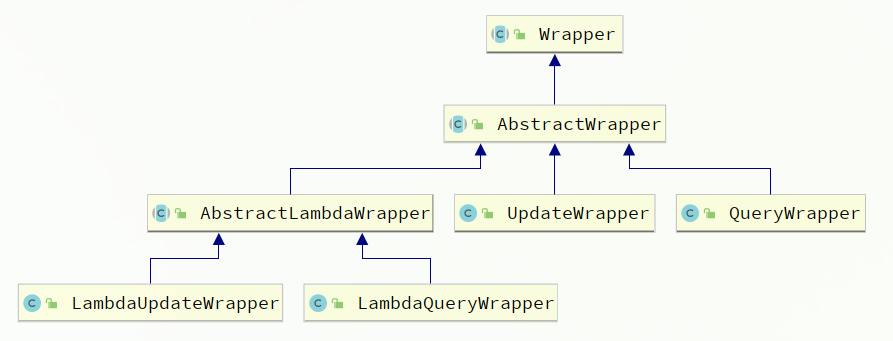

| 类型 | 主要用途 | 字段表达方式 |
| --- | --- | --- |
| `QueryWrapper<T>» | 查询列、构建 WHERE 条件 | 字符串列名，例如 `"username"» |
| `LambdaQueryWrapper<T>» | 构建查询条件及选择列 | 方法引用，例如 `User::getUsername» |
| `UpdateWrapper<T>» | WHERE 条件和特殊 SET 表达式 | 字符串列名 |
| `LambdaUpdateWrapper<T>» | 更新条件及 SET 赋值 | 方法引用，可配合受控 `setSql» |

Lambda 方法引用让字段名与实体属性关联，重命名属性时 IDE 更容易发现问题。普通字符串 Wrapper 写的是数据库列名，不能把 `"createTime"» 当成 `"create_time"»。

| 方法 | 条件含义 | 示例 SQL |
| --- | --- | --- |
| `eq / ne» | 等于 / 不等于 | `status = ?» |
| `gt / ge / lt / le» | 大于 / 大于等于 / 小于 / 小于等于 | `balance >= ?» |
| `like» | 两侧模糊匹配 | `username LIKE '%o%'» |
| `likeRight / likeLeft» | 前缀 / 后缀匹配 | `'Ja%'» / `'%ck'» |
| `between» | 包含上下界的范围 | `balance BETWEEN ? AND ?» |
| `in» | 集合内匹配 | `id IN (?, ?, ?)» |
| `isNull / isNotNull» | 空值 / 非空值 | `phone IS NULL» |
| `orderByAsc / orderByDesc» | 排序 | `ORDER BY balance DESC» |
| `and / or» | 组合逻辑 | 复杂条件应通过嵌套表达括号 |
| `select» | 选择返回列 | `SELECT id, username» |

连续条件通常用 AND 连接。需要 `status=1 AND (name like ... OR balance>=...)» 时，应显式嵌套：

```java
Wrappers.<User>lambdaQuery()
    .eq(User::getStatus, 1)
    .and(w -> w.like(User::getUsername, "o")
               .or().ge(User::getBalance, 1000));
```

Wrapper 会积累条件，每次业务操作应创建新对象，不应作为共享成员被多个请求反复修改。


## 8. 条件查询与特殊更新

课件通过“查名字含 o 且余额不少于 1000 的用户”和“批量扣减余额”展示 Wrapper 的用途。（课件第 20—22 页）

**整理示例：选择部分列并查询**：

```java
LambdaQueryWrapper<User> query = Wrappers.<User>lambdaQuery()
    .select(User::getId, User::getUsername, User::getInfo, User::getBalance)
    .like(User::getUsername, "o")
    .ge(User::getBalance, 1000);
List<User> users = userMapper.selectList(query);
```

对应 SQL 结构：

```sql
SELECT id, username, info, balance
FROM user
WHERE username LIKE ? AND balance >= ?;
```

只选部分列时，未选属性没有加载，不能再把这个对象当成完整用户数据。

**固定值更新**：

```java
userMapper.update(null,
    Wrappers.<User>lambdaUpdate()
        .eq(User::getUsername, "jack")
        .set(User::getBalance, 2000));
```

**课件算术更新**：

```java
List<Long> ids = List.of(1L, 2L, 4L);
UpdateWrapper<User> update = new UpdateWrapper<User>()
    .setSql("balance = balance - 200")
    .in("id", ids);
userMapper.update(null, update);
```

`set» 用于给列赋一个值；`setSql» 用于表达“数据库当前余额减 200”。这里的 SQL 由后端固定书写。金额来自请求时，更容易审查的做法是下一节的 `#{amount}» 参数绑定，不应直接拼接请求字符串。

> 通用 Wrapper 负责表达条件，不负责识别“余额不能为负”等业务规则。上述课件算术更新没有余额、状态校验，只适合演示 API。


## 9. Wrapper 与自定义 SQL

复杂更新或统计 SQL 可以保留 MyBatis XML，同时复用 Wrapper 构建条件。（课件第 24—26 页）

```text
后端生成的 Wrapper → WHERE 条件及绑定参数
手写 Mapper XML    → UPDATE / SELECT / JOIN / GROUP BY 等主体
MyBatis            → 组合 SQL 并绑定参数
```

**课件方案整理**：

```java
public interface UserMapper extends BaseMapper<User> {
    int updateBalanceByIds(
        @Param(Constants.WRAPPER) LambdaQueryWrapper<User> wrapper,
        @Param("amount") int amount);
}
```

`Constants.WRAPPER» 的值是 `"ew"»，等价于课件的 `@Param("ew")»。`@Param» 来自 MyBatis。

```xml
<mapper namespace="com.itheima.mp.mapper.UserMapper">
    <update id="updateBalanceByIds">
        UPDATE user
        SET balance = balance - #{amount}
        ${ew.customSqlSegment}
    </update>
</mapper>
```

```java
List<Long> ids = List.of(1L, 2L, 4L);
if (ids == null || ids.isEmpty()) {
    throw new IllegalArgumentException("用户ID集合不能为空");
}
LambdaQueryWrapper<User> wrapper = Wrappers.<User>lambdaQuery()
    .in(User::getId, ids);
int rows = userMapper.updateBalanceByIds(wrapper, 200);
```

| 写法 | 处理方式 | 使用边界 |
| --- | --- | --- |
| `#{amount}» | 作为预编译参数绑定 | 用于金额、用户名等值 |
| `${ew.customSqlSegment}» | 将 Wrapper 生成的 SQL 片段嵌入语句 | Wrapper 必须由可信后端逻辑构建 |
| `${前端原始字符串}» | 直接拼接原文 | 不应用来接受任意条件、列名或排序 SQL |

普通条件下，`customSqlSegment» 会带上 WHERE，不要再无条件手写一个 WHERE。字段名、`setSql»、`apply»、`last» 等 SQL 片段必须受后端控制。自定义 SQL 也不要假设会自动获得通用 Mapper 的全部逻辑删除等行为，应检查最终 SQL。


## 10. 多表关联：别名、重复行与结果映射

“查询地址在北京且 ID 在指定集合中的用户”已经跨越 `user» 与 `address»，单表通用方法不直接表达 JOIN。（课件第 27 页，隐藏页）

**课件思路**是 `user u INNER JOIN address a ON u.id=a.user_id»，再筛选用户 ID 与城市。落地时要注意两点：

| 问题 | 原因 | 处理方式 |
| --- | --- | --- |
| 两表都存在 `id» 等同名列 | `SELECT *» 结果列含义不明确 | 显式选择 `u» 的列或为地址列起别名 |
| 一个用户有多个北京地址 | JOIN 后同一用户出现多行 | 只要用户时使用 DISTINCT 或 EXISTS |

**改进示例**：只判断是否存在地址，用 EXISTS 更直接：

```xml
<select id="queryUsersByCity"
        resultType="com.itheima.mp.domain.po.User">
    SELECT u.id, u.username, u.info, u.status, u.balance
    FROM user u
    WHERE u.id IN
    <foreach collection="ids" item="id"
             open="(" separator="," close=")">
        #{id}
    </foreach>
    AND EXISTS (
        SELECT 1 FROM address a
        WHERE a.user_id = u.id
          AND a.city = #{city}
          AND a.deleted = 0
    )
</select>
```

Mapper 参数应声明 `@Param("ids")» 与 `@Param("city")»，Service 先处理空 ID 集合。这里返回的是投影用户信息，未选择密码等列。

若坚持 JOIN 并使用 Wrapper，普通 `QueryWrapper» 可以显式写 `"u.id"»、`"a.city"»。Lambda Wrapper 根据实体解析字段，通常不会自动理解手写 SQL 的表别名和另一个表的属性。跨表筛选不能简单照搬单表条件。


## 11. IService 与业务 Service

Controller 需要用户业务接口，而不是到处重复调用 Mapper。MP 提供 `IService» 和 `ServiceImpl»，给 Service 层提供通用 CRUD 与批处理能力。（课件第 29—33 页）

```java
public interface IUserService extends IService<User> {
    void deductBalance(Long id, Integer money);
}

@Service
public class UserServiceImpl
        extends ServiceImpl<UserMapper, User>
        implements IUserService {
    // baseMapper 是继承获得的 UserMapper
    // 在这里实现 deductBalance 等业务方法
}
```

| 操作 | Service 方法 | 与 Mapper 的区别 |
| --- | --- | --- |
| 新增 / 批量新增 | `save» / `saveBatch» | 通常返回 `boolean» |
| 按 ID 删除 / 批量删除 | `removeById» / `removeByIds» | 包装 Mapper 删除能力 |
| 按 ID 更新 / 批量更新 | `updateById» / `updateBatchById» | 批量更新仍需每个对象有 ID |
| 按 ID 查询 / 批量查询 | `getById» / `listByIds» | 返回实体 / 列表 |
| 条件查询 | `list»、`getOne»、`count» | 单条查询应保证条件唯一 |
| 分页 | `page» | 配合分页插件 |
| 新增或修改 | `saveOrUpdate» / `saveOrUpdateBatch» | 按主键等规则判断，不等价于数据库原子 UPSERT |
| 链式条件 | `lambdaQuery» / `lambdaUpdate» | 构建后以 `list/getOne/update» 等结束 |

`getOne(wrapper)» 在匹配多行时通常抛出异常；允许不抛异常也不能把不明确的匹配变成可靠的业务规则，应建立唯一约束或明确排序与限制。

**判断原则**：通用方法解决数据访问复用，业务 Service 仍负责校验、事务和业务状态变化。不能因为继承了 `IService»，就把所有数据库操作无条件暴露成 HTTP 接口。


## 12. REST 接口与 DTO、PO、VO

直接把数据库实体当成请求和响应，会让密码、内部状态等字段跟随接口泄漏，也会让客户端控制不该修改的列。课件要求使用用户表单和用户 VO。（课件第 34 页）

| 对象 | 作用 | 示例 |
| --- | --- | --- |
| DTO | 接收一次业务请求的数据 | `UserFormDTO»、`UserQuery» |
| PO | 表示持久化数据，映射数据库 | `User» |
| VO | 表示返回给调用方的数据 | `UserVO»，排除密码 |

| 接口 | 方法与路径 | 参数 | 返回 |
| --- | --- | --- | --- |
| 新增用户 | POST `/users» | 用户表单 JSON | 课件无返回体 |
| 删除用户 | DELETE `/users/{id}» | 路径 ID | 无 |
| 查询一个用户 | GET `/users/{id}» | 路径 ID | `UserVO» |
| 批量查询用户 | GET `/users?ids=1,2,4» | ID 集合 | `List<UserVO>» |
| 扣减余额 | PUT `/users/{id}/deduction/{money}» | 用户 ID、金额 | 无 |

**整理示例：查询入口**：

```java
@RestController
@RequestMapping("/users")
@RequiredArgsConstructor
public class UserController {
    private final IUserService userService;

    @GetMapping("/{id}")
    public UserVO queryById(@PathVariable Long id) {
        User user = userService.getById(id);
        if (user == null) {
            throw new ResponseStatusException(HttpStatus.NOT_FOUND, "用户不存在");
        }
        return UserVO.from(user); // 自定义显式转换方法
    }

    @GetMapping
    public List<UserVO> queryByIds(@RequestParam List<Long> ids) {
        if (ids.isEmpty()) {
            return Collections.emptyList();
        }
        return userService.listByIds(ids).stream()
            .map(UserVO::from)
            .collect(Collectors.toList());
    }
}
```

`UserVO.from» 是本篇整理示例约定的方法，需要在项目中实现，不能误认为 MP 自动提供。新增时应校验 DTO，并完成密码哈希；返回时只映射允许展示的属性。批量查询还应限制 ID 数量。


## 13. Lambda 链式查询与动态条件

用户搜索允许名字、状态和余额上下界分别为空。动态条件让一个接口覆盖这些组合，而无需为每个组合手写一条 SQL。（课件第 35 页）

**整理示例**，`UserQuery» 含 `name»、`status»、`minBalance»、`maxBalance» 四个可选属性：

```java
public List<User> queryUsers(UserQuery q) {
    if (q.getMinBalance() != null && q.getMaxBalance() != null
            && q.getMinBalance() > q.getMaxBalance()) {
        throw new IllegalArgumentException("最小余额不能大于最大余额");
    }
    return lambdaQuery()
        .like(StringUtils.hasText(q.getName()),
              User::getUsername, q.getName())
        .eq(q.getStatus() != null,
            User::getStatus, q.getStatus())
        .ge(q.getMinBalance() != null,
            User::getBalance, q.getMinBalance())
        .le(q.getMaxBalance() != null,
            User::getBalance, q.getMaxBalance())
        .list();
}
```

`StringUtils.hasText» 此处使用 Spring 的工具类。条件方法第一个 `boolean» 参数控制该条件是否加入 SQL。

| 传入条件 | 应生成的余额筛选 |
| --- | --- |
| 仅 `minBalance=1000» | `balance >= 1000» |
| 仅 `maxBalance=2000» | `balance <= 2000» |
| 两个边界都传入 | 同时满足上下界 |
| 两个边界都为空 | 不加余额条件 |

课件 XML 在两个边界同时存在时使用 BETWEEN。整理示例改用独立 `ge/le»，补足只传一个边界的情况。状态改为枚举类型后，查询 DTO 也应转换为对应枚举再比较。


## 14. Lambda 更新：余额扣减与并发边界

余额更新既要操作字段，也要遵守状态规则。课件要求：校验用户存在、状态正常和余额充足；扣减后余额为 0 时，将状态改为冻结 `2»。（课件第 36 页）

**课件业务流程的整理示例**，此处 `status» 仍为 Integer：

```java
@Override
public void deductBalance(Long id, Integer money) {
    if (money == null || money <= 0) {
        throw new IllegalArgumentException("扣减金额必须大于0");
    }
    User user = getById(id);
    if (user == null) {
        throw new IllegalArgumentException("用户不存在");
    }
    if (!Integer.valueOf(1).equals(user.getStatus())) {
        throw new IllegalStateException("用户已冻结或状态异常");
    }
    if (user.getBalance() == null || user.getBalance() < money) {
        throw new IllegalStateException("余额不足");
    }
    int remaining = user.getBalance() - money;
    boolean success = lambdaUpdate()
        .eq(User::getId, id)
        .set(User::getBalance, remaining)
        .set(remaining == 0, User::getStatus, 2)
        .update();
    if (!success) {
        throw new IllegalStateException("扣减失败");
    }
}
```

**并发问题**：两个请求可能同时读到余额 1000，各扣 800，最后都写入 200。请求都成功，但总扣减没有准确反映到账户。普通事务注解只把操作放进事务，不能自动解决这一“先读后改”的竞态。

**补充/改进：由数据库原子校验并扣减**，适用于配套 MySQL/InnoDB：

```java
int deductBalance(@Param("id") Long id, @Param("money") int money);
```

```xml
<update id="deductBalance">
    UPDATE user
    SET status = CASE WHEN balance = #{money} THEN 2 ELSE status END,
        balance = balance - #{money}
    WHERE id = #{id}
      AND status = 1
      AND balance >= #{money}
</update>
```

Service 先校验 `money > 0»，执行后要求影响行数为 `1»。为 `0» 表示用户不存在、状态异常或余额不足，可统一返回扣减失败，或按业务需要另查原因。

这里先计算 `status»，再修改 `balance»，避免 MySQL 单表 UPDATE 赋值顺序影响 CASE 对原余额的判断。余额校验与修改在同一条 SQL 内完成，能防止上述并发超扣。另一种方案是在事务内先 `SELECT ... FOR UPDATE» 锁住记录，再判断和更新。

> 原子扣减解决并发修改一致性。付款类业务还需要用业务单号等实现幂等，防止同一请求重试后重复扣款；课件并未实现完整支付流程。


## 15. 批量新增与 JDBC 批处理

插入 10 万条数据时，每条都单独发送和提交会产生大量往返开销。课件对比普通循环、`saveBatch» 和开启 JDBC 重写参数后的批处理。（课件第 37 页）

| 方案 | 执行特点 | 使用判断 |
| --- | --- | --- |
| for 循环逐条 `save» | 多次单条操作，往返成本高 | 小量功能验证可以使用 |
| `saveBatch(list, batchSize)» | 基于 JDBC 批处理组织执行 | 适合批量写入 |
| 批处理 + `rewriteBatchedStatements=true» | MySQL 驱动在适用时重写批量语句 | 可进一步减少交互，需按环境实测 |

```yaml
spring:
  datasource:
    url: jdbc:mysql://localhost:3306/mp?rewriteBatchedStatements=true
```

URL 已有参数时用 `&rewriteBatchedStatements=true» 追加。

**整理示例**，`userChunk» 是一批已校验、用户名不重复且字段完整的用户：

```java
boolean success = userService.saveBatch(userChunk, 1000);
```

`batchSize» 控制批处理分段，并不意味着每段自动成为独立事务。超大数据量应分段生成和处理，结合事务边界控制内存、锁和失败回滚成本。

比较性能时应保持数据量、驱动版本、表索引和事务方式一致。`saveBatch» 也不等于任何情况下都生成一条多 values INSERT；实际行为由执行器、驱动和 SQL 决定。课件没有给出可复用的具体耗时，因此本篇不写虚构的倍数。


## 16. 代码生成器：从表结构生成基础代码

实体、Mapper 和通用 Service 的结构比较固定，可以从数据库元信息生成，再补充业务规则。（课件第 40—43 页）

课件使用 IDEA 插件市场中的 **`MyBatisPlus» 插件**，截图显示作者为 MybatisPlus、版本 1.7.2。这是课件当时的 IDE 插件操作方式，菜单和兼容性会随 IDEA、插件版本变化，不代表 MP starter 自带同样的界面。

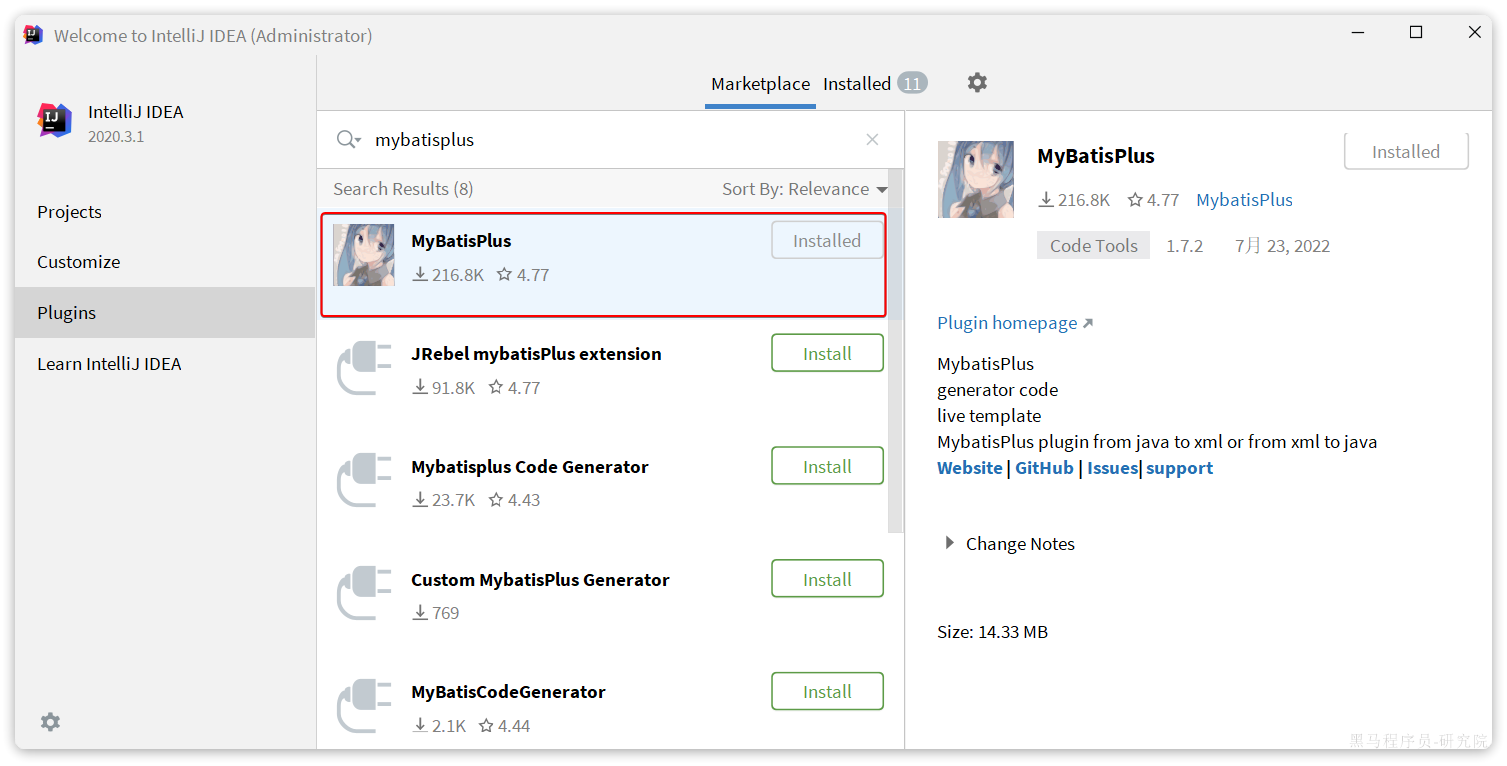

课件操作顺序：

1. 安装匹配 IDEA 版本的插件。
2. 通过 `Other → Config Database» 配置数据库连接并测试。
3. 通过 `Other → Code Generator» 打开生成界面，选择需要的表。
4. 指定生成代码的包路径、实体和 Mapper 等目录，确认主键策略。
5. 生成后检查实体映射与业务接口，再按需求修改。

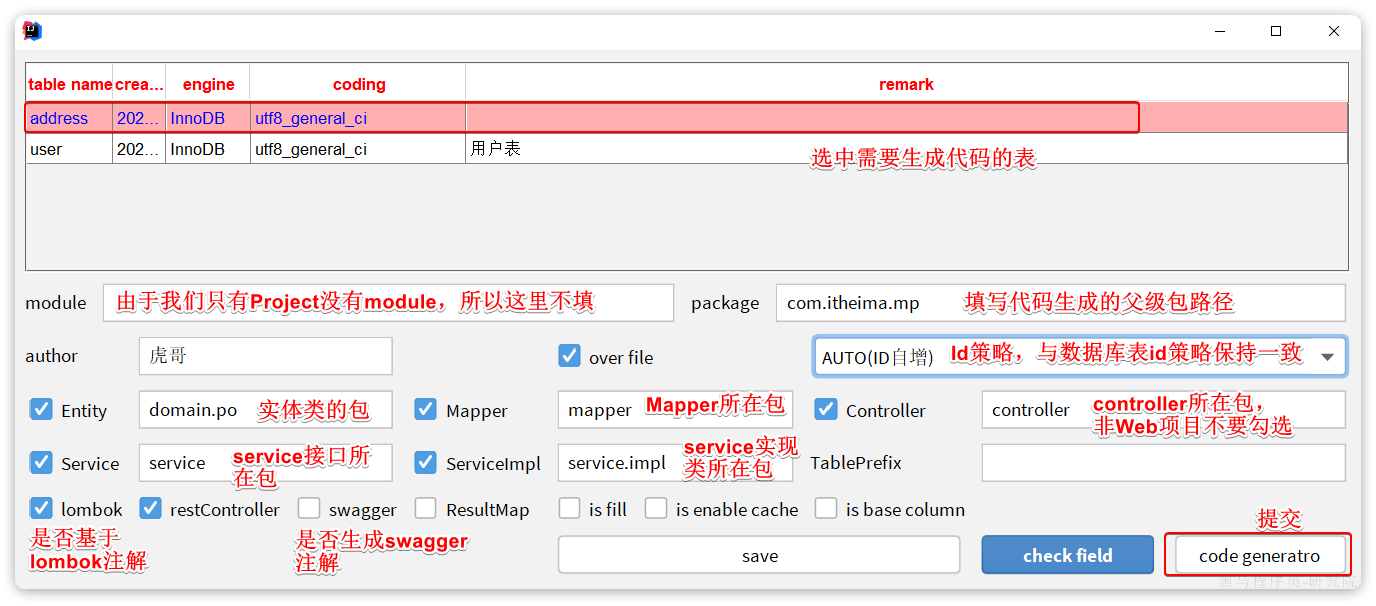

| 生成配置 | 课件含义 | 实际检查 |
| --- | --- | --- |
| `module» / `package» | 模块与父包 | 多模块项目不能生成到错误模块 |
| Entity / Mapper | 实体和 Mapper 的包 | 类名、表名、列映射正确 |
| Service / ServiceImpl | 业务接口与实现包 | 正确继承 `IService / ServiceImpl» |
| Controller | 可选接口层 | 仅生成需要的接口 |
| ID 策略 | 自增或分配 ID | 与数据库主键设计一致 |
| `tablePrefix» | 处理表名前缀 | `tb_» 等前缀是否需要去掉 |
| Lombok / Swagger | 是否生成对应注解 | 项目是否具备相关依赖 |
| `over file» | 覆盖已有文件 | 已写业务代码时应关闭并审查差异 |

生成器根据“表结构 + 配置 + 模板”生成基础代码。密码不返回、权限校验、金额规则、DTO/VO 分离等业务要求仍需开发者补充。看见生成成功后，至少核对字段类型、主键策略、非表字段、JSON/枚举处理及默认开放的接口。


## 17. Db 静态工具

用户 Service 想查询地址，地址 Service 又需要检查用户状态，互相注入容易形成循环依赖。课件用 `Db» 静态工具演示直接访问另一实体对应的 Mapper 能力。（课件第 45—46 页）

`Db» 位于 `com.baomidou.mybatisplus.extension.toolkit.Db»，可以根据实体类型找到已注册的 Mapper。**它仍依赖 Spring/MyBatis 已初始化对应 Mapper**，不是独立的数据库客户端。

| 操作 | 整理示例 |
| --- | --- |
| 按 ID 查询 | `Db.getById(id, User.class)» |
| 批量查 ID | `Db.listByIds(ids, User.class)» |
| 保存 / 修改 | `Db.save(user)» / `Db.updateById(user)» |
| 删除 | `Db.removeById(id, User.class)» |
| 条件计数 | `Db.lambdaQuery(User.class).eq(...).count()» |
| 条件列表 | `Db.lambdaQuery(Address.class).eq(...).list()» |
| 链式更新 | `Db.lambdaUpdate(User.class).eq(...).set(...).update()» |

**整理示例**：

```java
List<Address> addresses = Db.lambdaQuery(Address.class)
    .eq(Address::getUserId, userId)
    .list();
```

需要 `AddressMapper extends BaseMapper<Address>» 已被扫描。上例是否自动过滤已删除地址，取决于下一节的逻辑删除映射是否已经配置。

**边界**：`Db» 可以减少简单数据查询造成的互相注入，但绕过另一个 Service 时，也会绕过其业务校验。涉及“冻结用户禁止查询地址”这类规则，应保留明确的业务服务入口，或由上层组合服务协调用户和地址查询。


## 18. 查询用户及地址：一次组装与批量组装

返回用户信息及全部地址时，需要把数据库的两类记录组合为一个 VO。课件同时要求支持单用户和批量用户查询，并练习“冻结用户查询地址抛异常”。（课件第 46 页）

```text
单用户：查用户 → 查该用户地址 → 组装 UserVO
批量用户：一次查用户 → 一次按用户ID查地址 → 按 user_id 分组 → 组装多个 UserVO
```

如果查 N 个用户后，为每个用户单独查地址，会形成 **N+1 次查询**：一次查用户，N 次查地址。

**批量组装整理示例**，`UserVO.from» 和 `AddressVO.from» 均为自定义转换方法：

```java
public List<UserVO> queryUsersWithAddresses(List<Long> ids) {
    if (ids == null || ids.isEmpty()) {
        return Collections.emptyList();
    }
    List<User> users = listByIds(ids);
    if (users.isEmpty()) {
        return Collections.emptyList();
    }
    List<Long> foundIds = users.stream()
        .map(User::getId).collect(Collectors.toList());

    List<Address> addresses = Db.lambdaQuery(Address.class)
        .in(Address::getUserId, foundIds)
        .list();
    Map<Long, List<AddressVO>> grouped = addresses.stream()
        .collect(Collectors.groupingBy(
            Address::getUserId,
            Collectors.mapping(AddressVO::from, Collectors.toList())));

    return users.stream().map(user -> {
        UserVO vo = UserVO.from(user);
        vo.setAddresses(grouped.getOrDefault(
            user.getId(), Collections.emptyList()));
        return vo;
    }).collect(Collectors.toList());
}
```

该示例假设地址实体已配置逻辑删除，否则应显式过滤 `deleted=0»。大 ID 集合需要控制大小或分段查询。

**练习规则整理**：地址查询入口先查用户；不存在时返回不存在错误；状态为冻结时抛业务异常；正常才查询地址。若 `status» 已改成 `UserStatus»，应比较 `UserStatus.NORMAL»，不再比较整数 `1»。


## 19. 逻辑删除：数据保留与查询过滤

需要保留历史数据时，可以把删除操作改成更新标记。**逻辑删除只改变可见状态，数据仍保留在原表中**。（课件第 48—49 页）

| 操作 | 物理删除 | 逻辑删除示意 |
| --- | --- | --- |
| 删除 | `DELETE FROM address WHERE id=?» | `UPDATE address SET deleted=1 WHERE id=? AND deleted=0» |
| 普通查询 | 查询仍存在的行 | 增加 `deleted=0» 过滤 |
| 数据保留 | 记录已移除 | 原记录仍在表中 |

**课件全局配置**：

```yaml
mybatis-plus:
  global-config:
    db-config:
      logic-delete-field: flag
      logic-delete-value: 1
      logic-not-delete-value: 0
```

`logic-delete-field» 指的是 **Java 实体属性名**。课件中的 `flag» 只是示例名，配套 `address» 表实际使用 `deleted»；`user» 表没有对应列。

**按配套 SQL 整理的实体方案**：

```java
@Data
@TableName("address")
public class Address {
    @TableId(type = IdType.AUTO)
    private Long id;
    private Long userId;
    private String province;
    private String city;
    private String town;
    private String mobile;
    private String street;
    private String contact;
    @TableField("is_default")
    private Boolean isDefault;
    private String notes;

    @TableLogic(value = "0", delval = "1")
    private Boolean deleted;
}
```

也可把全局字段改为 `deleted»，无需再重复为每个实体配置 `@TableLogic»。实体注解适合只有部分表采用逻辑删除的项目。

MP 的通用查询会过滤逻辑删除行，通用删除转为标记更新；自定义 XML、JOIN 和原生 SQL 应自行核对过滤条件。

| 代价 | 为什么需要关注 | 常见做法 |
| --- | --- | --- |
| 历史数据持续增长 | 查询和索引维护成本可能增加 | 定期归档，设计合适索引 |
| 唯一约束仍占用 | 已删除用户名等值仍在表中 | 明确恢复与重复创建规则 |
| 查询容易漏过滤 | 自定义 SQL 未必自动改写 | 在数据访问层统一约定 |
| 统计口径复杂 | “全部”是否包含已删除数据 | 明确业务语义 |

课件更倾向历史表迁移方案，这是一种架构取舍。需要恢复、审计或保留关联关系时，逻辑删除仍可能合适；不能把“不推荐”理解为所有项目都应禁用。


## 20. 通用枚举：数据库值与接口显示值

在代码中到处写 `status=1/2» 容易混淆。枚举把有限状态命名，再由类型处理器完成 Java 枚举与数据库值的转换。（课件第 51—54 页）

**整理示例**：

```java
@Getter
public enum UserStatus {
    NORMAL(1, "正常"),
    FREEZE(2, "冻结");

    @EnumValue
    private final int value;

    @JsonValue
    private final String desc;

    UserStatus(int value, String desc) {
        this.value = value;
        this.desc = desc;
    }
}
```

实体中的 `private Integer status» 改为：

```java
private UserStatus status;
```

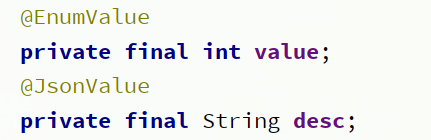

| 注解 | 所属机制 | 结果 |
| --- | --- | --- |
| `@EnumValue» | MP 的枚举数据库映射 | 数据库保存 `1» 或 `2» |
| `@JsonValue» | Jackson 的 JSON 序列化 | 对外 JSON 可显示“正常”或“冻结” |

两个注解分别处理数据库和 HTTP JSON，不能互相替代。`@JsonValue» 也会影响枚举反序列化契约，接口若接收 `1/2»，应使用独立 DTO 或明确转换规则。只想改变响应文案时，也可以在 VO 转换阶段生成状态描述。

**课件显式配置**：

```yaml
mybatis-plus:
  configuration:
    default-enum-type-handler: com.baomidou.mybatisplus.core.handlers.MybatisEnumTypeHandler
```

**版本说明**：MP 3.5.2 起默认使用 `CompositeEnumTypeHandler»，对标记 `@EnumValue» 或实现 `IEnum» 的通用枚举选择 MP 枚举处理方式；未声明的枚举默认按普通枚举处理。因而本篇 3.5.3.1 下，通用枚举映射不应被解释为“必须先全局替换处理器才能工作”。保留课件配置便于对照，实际项目应核对版本及是否还存在普通枚举。

改为枚举后，赋值和条件同步调整，例如 `user.setStatus(UserStatus.NORMAL)»、`eq(User::getStatus, UserStatus.NORMAL)»。数据库存在未定义状态值时，应明确数据清理或异常处理策略。


## 21. JSON 类型处理器

`info» 保存年龄、简介和性别时，用字符串会让业务代码到处解析 JSON。类型处理器负责 **Java 对象与数据库 JSON 文本之间的转换**。（课件第 55—56 页）

**整理示例**：

```java
@Data
public class UserInfo {
    private Integer age;
    private String intro;
    private String gender;
}

@Data
@TableName(value = "user", autoResultMap = true)
public class User {
    @TableId(type = IdType.AUTO)
    private Long id;
    private String username;
    // 其余字段省略，沿用前面的 User 实体

    @TableField(typeHandler = JacksonTypeHandler.class)
    private UserInfo info;

    private UserStatus status;
}
```



| 配置 | 作用 |
| --- | --- |
| `JacksonTypeHandler» | 借助 Jackson 序列化和反序列化 `info» |
| `@TableField(typeHandler=...)» | 声明该字段使用的处理器 |
| `@TableName(autoResultMap=true)» | 让 MP 生成包含字段处理器的结果映射 |

保存时 `user.setInfo(userInfo)»，查询后直接使用 `user.getInfo().getAge()»。数据库中的结构仍然是：

```json
{
  "age": 20,
  "intro": "佛系青年",
  "gender": "male"
}
```

`JacksonTypeHandler» 需要 Jackson 依赖，Spring Boot Web 项目通常已有；应核对实际依赖。自定义 XML 如果只写 `resultType»，不要假设一定复用实体生成的结果映射，可显式编写 `resultMap» 并为 `info» 指定处理器。

JSON 映射解决存取转换，不会自动实现 JSON 内部字段的索引、筛选或表结构约束。频繁按年龄筛选时，还需判断应使用普通列、生成列或合适的 JSON 查询与索引。


## 22. 配置加密：密文、密钥与启动参数

课件展示 MP 从 3.3.2 起提供的 AES 配置加密工具，避免在配置文件中直接存放明文数据源用户名和密码。（课件第 58—61 页，隐藏页）

| 概念 | 含义 | 放在哪里 |
| --- | --- | --- |
| 明文 | 原始配置值 | 仅在生成密文或运行时使用 |
| 密钥 | 加密和解密使用的秘密值 | 与配置文件分离注入 |
| 密文 | 用密钥加密后的配置值 | 以 `mpw:» 前缀写入配置 |

课件第 59 页将替换配置的内容称为“秘钥”，这里应理解为 **密文**，真正的密钥通过启动参数提供。

**整理示例：生成密文**，用于本地一次性配置准备：

```java
String key = AES.generateRandomKey();
String encryptedUsername = AES.encrypt(
    System.getenv("DB_USERNAME"), key);
String encryptedPassword = AES.encrypt(
    System.getenv("DB_PASSWORD"), key);
// 将密文写入配置，将 key 保存到独立的受控密钥来源
// 不在应用正常运行日志中打印明文或 key
```

`AES» 来自 `com.baomidou.mybatisplus.core.toolkit.AES»。上述代码只展示工具调用，不是项目启动时每次重新生成密钥。

```yaml
spring:
  datasource:
    username: mpw:<生成的用户名密文>
    password: mpw:<生成的密码密文>
```

**课件启动方式整理**：

```text
java -jar mp-demo.jar --mpw.key=<生成密文时使用的同一密钥>
```

IDEA 中填入 **Program arguments**。这里采用应用参数 `--mpw.key»，不能误填成 Java 类名或把前缀写错。

课件还展示测试类配置 `@SpringBootTest(args="--mpw.key=...")»。学习时可理解为给测试启动上下文传入相同参数；实际项目不要把真实密钥硬编码进测试源码，应由测试环境或受控配置注入。

> 配置加密减少文件中的明文暴露，但应用运行时仍需要密钥。把密钥与密文一起提交仓库，无法达到隔离目的。它也不等于数据库字段加密或用户密码哈希。


## 23. 插件机制与常见内部拦截器

分页、多租户等能力需要在 SQL 执行前统一处理。MP 基于 MyBatis 的 `Interceptor» 实现 `MybatisPlusInterceptor»，内部维护多个 `InnerInterceptor»。（课件第 63—64 页，第 63 页为隐藏页）

```text
MyBatis 执行 query / update / prepare
            ↓
MybatisPlusInterceptor
            ↓
按配置顺序调用 InnerInterceptor
            ↓
执行改写或校验后的 SQL
```

| 内部拦截器 | 用途 | 应理解的边界 |
| --- | --- | --- |
| `TenantLineInnerInterceptor» | 添加租户隔离条件 | 需要可靠的租户上下文，检查绕过入口 |
| `DynamicTableNameInnerInterceptor» | 动态替换表名 | 表名应由后端规则生成 |
| `PaginationInnerInterceptor» | COUNT 查询和数据库分页 | 要配置数据库类型与页大小上限 |
| `OptimisticLockerInnerInterceptor» | 乐观锁更新 | 需要版本字段、`@Version» 和适用更新方法 |
| `IllegalSQLInnerInterceptor» | 检查部分 SQL 规范 | 不能替代实际性能分析 |
| `BlockAttackInnerInterceptor» | 拦截无条件全表更新和删除 | 是额外保护，仍需保证业务条件正确 |

乐观锁的典型逻辑是 `UPDATE ... SET version=version+1 WHERE id=? AND version=?»，影响行数为 0 时说明发生冲突，业务决定重试或失败。仅注册插件，没有版本字段和冲突处理，不能认为并发更新已经解决。

多个插件会互相影响 SQL。通常先处理多租户、动态表名等改写，再安排分页；分页插件放在其他 SQL 改写插件之后，便于 COUNT 处理最终条件。应以实际插件组合验证最终 SQL。


## 24. 分页插件的注册

返回全部用户会随数据增长拖慢接口。数据库分页只返回当前页的数据，MP 的分页插件负责生成适配数据库的分页 SQL。（课件第 65—68 页）

**课件配置整理**：

```java
@Configuration
public class MybatisConfig {
    @Bean
    public MybatisPlusInterceptor mybatisPlusInterceptor() {
        MybatisPlusInterceptor interceptor = new MybatisPlusInterceptor();
        PaginationInnerInterceptor pagination =
            new PaginationInnerInterceptor(DbType.MYSQL);
        pagination.setMaxLimit(1000L);
        interceptor.addInnerInterceptor(pagination);
        return interceptor;
    }
}
```

`MybatisPlusInterceptor» 是统一入口，`PaginationInnerInterceptor» 是其中的分页处理器。项目已有统一拦截器配置时，应在同一个配置中增加分页插件，避免重复注册。

| 设置 | 含义 |
| --- | --- |
| `DbType.MYSQL» | 按 MySQL 方言生成分页 |
| `maxLimit=1000L» | 设置单页最大条数 |
| 其他请求校验 | 限制页码、页大小，避免非法或过大的请求 |

本篇使用 MP 3.5.3.1，按课件依赖即可理解该配置。较新的 MP 版本存在分页解析依赖拆分，应根据所用版本核对，不能将新版本依赖要求倒套到课件。


## 25. Page 查询、排序与返回信息

`Page<T>» 同时携带分页请求参数和查询结果。通过 `service.page(page, wrapper)»，插件执行分页查询并回填总条数和当前页记录。（课件第 67—68 页）

**整理示例**：

```java
Page<User> page = Page.of(1, 5);  // 第1页，每页5条
page.addOrder(OrderItem.desc("balance"));
page.addOrder(OrderItem.asc("id")); // 补充：同余额时稳定排序

Page<User> result = userService.page(page);
long total = result.getTotal();
long pages = result.getPages();
List<User> records = result.getRecords();
```

`OrderItem» 的参数是数据库列名。课件的 `new OrderItem("balance", false)» 与 `OrderItem.desc("balance")» 表达相同的降序含义。

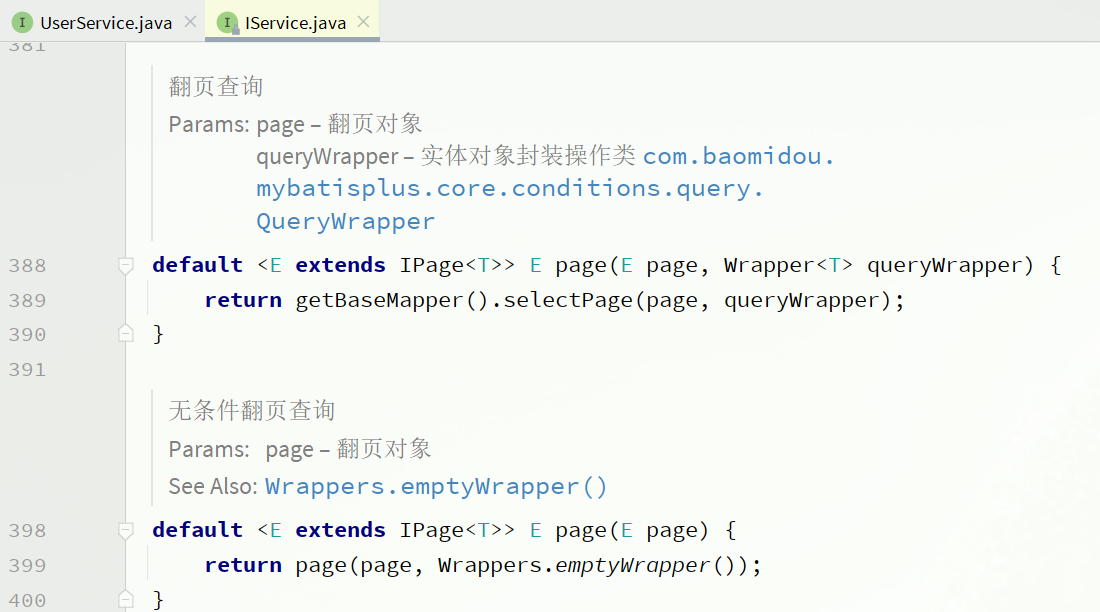

| 属性 | 含义 | 示例 |
| --- | --- | --- |
| `current» | 当前页，从 1 开始 | `2» |
| `size» | 每页条数 | `5» |
| `total» | 满足筛选条件的总记录数 | `12» |
| `pages» | 总页数 | `3» |
| `records» | 当前页数据 | 第 6—10 条 |

MySQL 分页大致使用 `LIMIT size OFFSET (current-1)*size»，总页数按总记录数和页大小向上取整。`Page» 默认通常执行 COUNT 再查当前页；若显式关闭 COUNT，就不能继续把总条数当作已统计结果。

**补充**：没有 ORDER BY 时，数据库不保证稳定顺序；只按可能重复的余额排序时，也可增加 ID 作为次序条件。大偏移分页和复杂 JOIN 的 COUNT 仍可能很慢，需要结合索引、执行计划及业务分页方式优化。


## 26. 用户分页接口与安全排序

课件要求 GET `/users/page»，支持页码、大小、排序和用户筛选，未指定排序字段时按更新时间排序。（课件第 70—71 页，第 71 页为隐藏页）

**请求示例**：

```text
GET /users/page?pageNo=1&pageSize=5&sortBy=balance&isAsc=false&name=jack&status=1
```

课件用对象展示参数结构；GET 接口通常把它们放在查询字符串中，再绑定到查询 DTO。

| 参数 | 含义 | 整理示例规则 |
| --- | --- | --- |
| `pageNo» | 当前页 | 默认 1，最小 1 |
| `pageSize» | 每页条数 | 默认 5，范围 1—1000 |
| `sortBy» | 对外排序字段 | 通过白名单映射数据库列 |
| `isAsc» | 是否升序 | 默认 false |
| `name» | 用户名关键词 | 非空才增加 LIKE |
| `status» | 用户状态 | 校验有效值并转换为枚举 |

排序字段通常不能用 `#{sortBy}» 绑定成 SQL 标识符，因此 **必须把请求值映射到后端白名单**。不能直接把任意客户端字符串交给 `OrderItem»、`orderBy» 或 `last»。

**整理示例：业务查询**，`toMpPage» 在下一节实现；此处实体已采用 `UserStatus»：

```java
public PageDTO<UserVO> queryUserPage(UserPageQuery q) {
    UserStatus status = null;
    if (q.getStatus() != null) {
        if (q.getStatus() == 1) {
            status = UserStatus.NORMAL;
        } else if (q.getStatus() == 2) {
            status = UserStatus.FREEZE;
        } else {
            throw new IllegalArgumentException("用户状态不合法");
        }
    }
    Page<User> page = q.toMpPage(
        Map.of("balance", "balance",
               "username", "username",
               "updateTime", "update_time"),
        "update_time");

    LambdaQueryWrapper<User> wrapper = Wrappers.<User>lambdaQuery()
        .like(StringUtils.hasText(q.getName()),
              User::getUsername, q.getName())
        .eq(status != null, User::getStatus, status);
    return PageDTO.of(page(page, wrapper), UserVO::from);
}
```

Controller 通过 `@GetMapping("/page")» 接收 `UserPageQuery»，调用上面的 Service 方法。`/users/page» 是固定路径，与 `/users/{id}» 并存时应保留明确的接口定义。

**课件返回结构**：外层为 `total / pages / list»，VO 中 `info» 是对象、`status» 是文案。以下数值仅作结构示例，不表示配套数据库的实际数据量：

```json
{
  "total": 1,
  "pages": 1,
  "list": [
    {
      "id": 1,
      "username": "Jack",
      "info": {"age": 20, "gender": "male", "intro": "佛系青年"},
      "status": "正常",
      "balance": 1600
    }
  ]
}
```

`UserVO.from» 应显式复制 `id / username / info / balance» 等允许返回的字段，并把状态转换为描述；不要复制密码。


## 27. 通用 PageQuery 与 PageDTO

每个分页接口都重新创建 Page、校验参数和转 VO，会产生重复代码。课件要求将请求转换放到 `PageQuery»，将结果转换放到 `PageDTO»。（课件第 72 页）

```text
UserPageQuery：页码、大小、排序 + 用户筛选
          ↓ toMpPage
Page<User> + Wrapper
          ↓ service.page
Page<User>：total、pages、records
          ↓ PageDTO.of + VO转换器
PageDTO<UserVO>：total、pages、list
```

**通用分页请求整理示例**：

```java
@Data
public class PageQuery {
    private Long pageNo = 1L;
    private Long pageSize = 5L;
    private String sortBy;
    private Boolean isAsc = false;

    public <T> Page<T> toMpPage(Map<String, String> allowedSorts,
                                String defaultColumn) {
        if (pageNo == null || pageNo < 1
                || pageSize == null || pageSize < 1 || pageSize > 1000) {
            throw new IllegalArgumentException("分页参数不合法");
        }
        String column = defaultColumn; // 由后端传入
        if (StringUtils.hasText(sortBy)) {
            column = allowedSorts.get(sortBy);
            if (column == null) {
                throw new IllegalArgumentException("不支持的排序字段");
            }
        }
        Page<T> page = Page.of(pageNo, pageSize);
        boolean ascending = Boolean.TRUE.equals(isAsc);
        page.addOrder(ascending ? OrderItem.asc(column)
                                : OrderItem.desc(column));
        if (!"id".equals(column)) {
            page.addOrder(OrderItem.asc("id"));
        }
        return page;
    }
}

@Data
@EqualsAndHashCode(callSuper = true)
public class UserPageQuery extends PageQuery {
    private String name;
    private Integer status;
}
```

白名单和默认列由各业务在后端传入。示例的 ID 次排序适用于本课的用户表；真正跨表复用时，主键列名和别名也应作为可信配置调整。

**通用分页响应整理示例**：

```java
@Data
public class PageDTO<T> {
    private long total;
    private long pages;
    private List<T> list;

    public static <P, V> PageDTO<V> of(
            IPage<P> page, Function<? super P, ? extends V> converter) {
        PageDTO<V> dto = new PageDTO<>();
        dto.setTotal(page.getTotal());
        dto.setPages(page.getPages());
        List<V> converted = new ArrayList<>();
        for (P record : page.getRecords()) {
            converted.add(converter.apply(record));
        }
        dto.setList(converted);
        return dto;
    }
}
```

`Function<P,V>» 表示把一个 PO 转成一个 VO 的函数。把转换器作为参数，可让分页封装复用于不同业务，并保留显式字段筛选。

空页返回 `list=[]»，同时保留总数、总页数；不要因为当前页没有记录就把 `total» 强行改为 0。这里把 MP 的 `records» 转成接口约定的 `list»，隔离框架对象与接口契约。


## 28. 练习验证与常见故障

以下是按课件与配套 SQL 整理的验证路线，**不表示已经执行过工程测试**。建议在练习数据库中按顺序完成，并区分每个操作带来的数据变化。

| 验证项 | 应观察的结果 |
| --- | --- |
| 原始数据基线 | SQL 初始有 4 个用户、11 条地址 |
| `selectById(1L)» | 原始数据为 Jack，余额 1600 |
| 查询 ID `1,2,4» | 返回 3 个存在的用户，不依赖返回顺序 |
| 名字含 o 且余额 ≥1000 | 未修改数据时匹配 Hope；实际匹配受数据库排序规则影响 |
| 只传余额下界 / 上界 | 对应条件各自生效 |
| 扣款后余额恰好为 0 | 状态变为冻结；无效金额与余额不足失败 |
| 并发扣款 | 原子更新方案不产生负余额或丢失扣减 |
| 查询用户及地址 | 批量组装使用两次批量查询，空地址返回空列表 |
| 地址逻辑删除 | 记录保留且通用查询过滤，不影响未配置删除字段的用户表 |
| 枚举 + JSON 往返 | 数据库存状态数值与 JSON，Java 得到枚举和对象 |
| 分页与排序 | 当前页条数正确，total 为筛选总量，非法排序字段被拒绝 |

| 现象 | 优先检查 |
| --- | --- |
| Mapper 注入失败 | Mapper 扫描路径、Spring 启动包、依赖冲突 |
| `Invalid bound statement» | XML 位置、namespace、方法名、`mapper-locations» |
| 报表或字段不存在 | `user/tb_user» 是否一致、注解和驼峰映射 |
| 更新 null 未生效 | 实体 `not_null» 策略，是否应显式 Wrapper `set» |
| JSON 查询还是字符串或映射失败 | 字段类型、处理器、`autoResultMap»、XML resultMap |
| 枚举转换失败 | 状态值、`@EnumValue»、依赖版本和全局处理器 |
| 分页返回全部或总数不对 | 分页插件是否注册、COUNT 是否关闭、JOIN 是否重复 |
| 配置无法解密 | `mpw:» 前缀、启动密钥与生成密文密钥是否相同 |


## 29. 核心回顾

| 看到的需求 | 首选判断路径 |
| --- | --- |
| 标准单表 CRUD | 实体映射 + `BaseMapper» |
| 单表复杂筛选 | Lambda Wrapper 或 Service 链式查询 |
| 算术更新、复杂关联、统计 | 评估自定义 SQL，复用受控 Wrapper |
| 多个业务步骤 | Service 校验与事务，另行分析并发 |
| 批量用户带地址 | 批量查询 + 分组组装 VO |
| 状态和 JSON 对象 | 类型处理器，区分数据库映射与 JSON 序列化 |
| 分页列表接口 | 插件 + Page + 排序白名单 + PageDTO |

**面试提示**：MyBatis-Plus 的通用 CRUD 基于实体元信息和 SQL 注入机制，Mapper 代理仍由 MyBatis 执行；Wrapper 组合条件，`IService» 复用通用 Service 能力。`AUTO» 与 `ASSIGN_ID» 的区别是数据库自增和框架分配 ID；`@EnumValue» 处理数据库值，`@JsonValue» 处理 JSON 表示；逻辑删除保留数据，需要考虑索引与唯一约束；分页依赖拦截器改写 SQL；批处理要结合 JDBC 和事务判断。涉及余额时，必须能解释为什么普通事务不能自动解决“先读后改”，以及条件原子更新、行锁或乐观锁分别解决什么问题。
